# Data-scaling experiment

Three surrogates trained on increasing amounts of 2019 data (96 h = Jul, 336 h = Jul-Sep,
600 h = Jul-Oct), evaluated on the **January 2019 winter episode** (`london_cm20190108-0109`,
a held-out out-of-distribution test for all three). We report pooled RMSE (ug/m3) and mean
per-level pattern correlation *r*, against a climatological baseline (each model's own
training-set per-cell mean PM2.5). Lower-level (15-75 m) and upper-level (95-195 m) spatial
comparisons are shown for a representative frame.

- 96 h  -> `data_scaling/ft_96`
- 336 h -> `future_transfer_mask`  (also the headline future-transfer model)
- 600 h -> `data_scaling/ft_600`


## Scaling metrics on the January episode

In [1]:
import sys, os; sys.path.insert(0,'../../src')
import numpy as np, torch
import matplotlib as mpl, matplotlib.pyplot as plt
from dataloader import PALMDatasetV2
from model import UNet3DFiLM
mpl.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','Liberation Serif','Nimbus Roman','DejaVu Serif'],
    'mathtext.fontset':'stix','axes.unicode_minus':False,'font.size':12})
NZ=12; ZH=[15,25,35,45,55,75,95,115,135,155,175,195]
dev=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SIM='london_cm20190108-0109'; NH=48          # January 2019 winter episode (held-out for all 3)
MODELS=[('ft_96', '96 h (Jul)',      '../../outputs/data_scaling/ft_96/checkpoints/best.pt'),
        ('ft_336','336 h (Jul-Sep)', '../../outputs/future_transfer_mask/checkpoints/best.pt'),
        ('ft_600','600 h (Jul-Oct)', '../../outputs/data_scaling/ft_600/checkpoints/best.pt')]
def pc(a,b):
    am=a-a.mean();bm=b-b.mean();d=np.sqrt((am**2).sum()*(bm**2).sum())
    return float((am*bm).sum()/d) if d>1e-9 else np.nan
def loadm(ckp):
    ck=torch.load(ckp,map_location='cpu',weights_only=False)
    m=UNet3DFiLM(in_ch=19,spatial_ch=3,base_ch=16,dropout=0.0,n_z=NZ,use_attention=True,n_down=4)
    m.load_state_dict(ck['model_state_dict']); m.to(dev).eval(); st=ck['norm_stats']
    mean=torch.tensor(st['pm25']['mean'][:NZ]).view(-1,1,1); std=torch.tensor(st['pm25']['std'][:NZ]).view(-1,1,1)
    return m,st,mean,std
# find the 600 h model's best frame (for the case figures)
m,st,mean,std=loadm(MODELS[-1][2])
dsf=PALMDatasetV2(sims=[SIM],mask_input=True,normalise=True,hour_filter={SIM:set(range(1,NH+1))},
                  global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); dsf._stats=st
IDX=-1; bestr=-1
with torch.no_grad():
    for i in range(len(dsf)):
        x,y,mk=dsf[i]; msk=mk.numpy().astype(bool)
        t=torch.expm1(y*std+mean).numpy(); p=torch.expm1(m(x.unsqueeze(0).to(dev)).cpu()[0]*std+mean).numpy()
        rr=[pc(t[z][msk[z]].astype(float),p[z][msk[z]].astype(float)) for z in range(NZ) if msk[z].sum()>10]
        mr=float(np.nanmean(rr))
        if mr>bestr: bestr=mr; IDX=i
# surrogate metrics (whole episode) for the 3 models + capture prediction at IDX
truth=None; preds=[]; surr={}
for key,lab,ckp in MODELS:
    m,st,mean,std=loadm(ckp)
    ds=PALMDatasetV2(sims=[SIM],mask_input=True,normalise=True,hour_filter={SIM:set(range(1,NH+1))},
                     global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ)); ds._stats=st
    sse=0.0;cnt=0;rs=[]
    with torch.no_grad():
        for i in range(len(ds)):
            _,_,_,th,dt=ds._index[i]
            x,y,mk=ds[i]; msk=mk.numpy().astype(bool)
            t=torch.expm1(y*std+mean).numpy(); p=torch.expm1(m(x.unsqueeze(0).to(dev)).cpu()[0]*std+mean).numpy()
            for z in range(NZ):
                s=msk[z];a=t[z][s].astype(np.float64);b=p[z][s].astype(np.float64)
                if a.size<10 or a.std()<1e-6: continue
                sse+=((b-a)**2).sum();cnt+=a.size; rs.append(pc(a,b))
            if i==IDX:
                if truth is None: truth=t; mask=msk; TIME=dt
                preds.append(p)
    surr[key]=(float(np.sqrt(sse/cnt)), float(np.mean(rs)))
print(f'January 2019 winter episode ({SIM})  |  figure frame {TIME:%Y-%m-%d %H:%M} (idx={IDX})\n')
for key,lab,_ in MODELS: print(f'  {lab:>14}: surrogate RMSE={surr[key][0]:6.2f}  r={surr[key][1]:.2f}')

January 2019 winter episode (london_cm20190108-0109)  |  figure frame 2019-01-08 04:00 (idx=3)

      96 h (Jul): surrogate RMSE=  7.25  r=0.53
  336 h (Jul-Sep): surrogate RMSE=  1.02  r=0.83
  600 h (Jul-Oct): surrogate RMSE=  0.72  r=0.84


## Table: surrogate vs climatological baseline

In [2]:
# Scaling table: surrogate vs climatological baseline (January episode).
# Baseline = each model's OWN training-set per-cell mean PM2.5 (precomputed, outputs/data_scaling/climatology.npz).
clim=np.load('../../outputs/data_scaling/climatology.npz')
dsb=PALMDatasetV2(sims=[SIM],mask_input=True,normalise=False,hour_filter={SIM:set(range(1,NH+1))},
                  global_pm_norm=False,em_bg_norm=True,t_hist=1,z_range=(0,NZ))
EP=[]
for i in range(len(dsb)):
    _,y,mk=dsb[i]; EP.append((np.expm1(y.numpy()).astype(np.float64), mk.numpy().astype(bool)))
base={}
for key,lab,_ in MODELS:
    cl=clim[key].astype(np.float64); s=0.0;c=0;rr=[]
    for t,msk in EP:
        for z in range(NZ):
            sel=msk[z]; a=t[z][sel]; b=cl[z][sel]
            if a.size<10 or a.std()<1e-6: continue
            s+=((b-a)**2).sum(); c+=a.size; rr.append(pc(a,b))
    base[key]=(float(np.sqrt(s/c)), float(np.mean(rr)))
print(f'{"Training data":>16} | {"Surrogate RMSE":>14} {"r":>6} | {"Baseline RMSE":>13} {"r":>6}')
print('-'*62)
for key,lab,_ in MODELS:
    print(f'{lab:>16} | {surr[key][0]:>14.2f} {surr[key][1]:>6.2f} | {base[key][0]:>13.2f} {base[key][1]:>6.2f}')

   Training data | Surrogate RMSE      r | Baseline RMSE      r
--------------------------------------------------------------
      96 h (Jul) |           7.25   0.53 |          2.55   0.25
 336 h (Jul-Sep) |           1.02   0.83 |          2.39   0.42
 600 h (Jul-Oct) |           0.72   0.84 |          2.64   0.52


## Case figure - lower levels (15-75 m)

saved figs/case_jan08_3models_perlevel.png


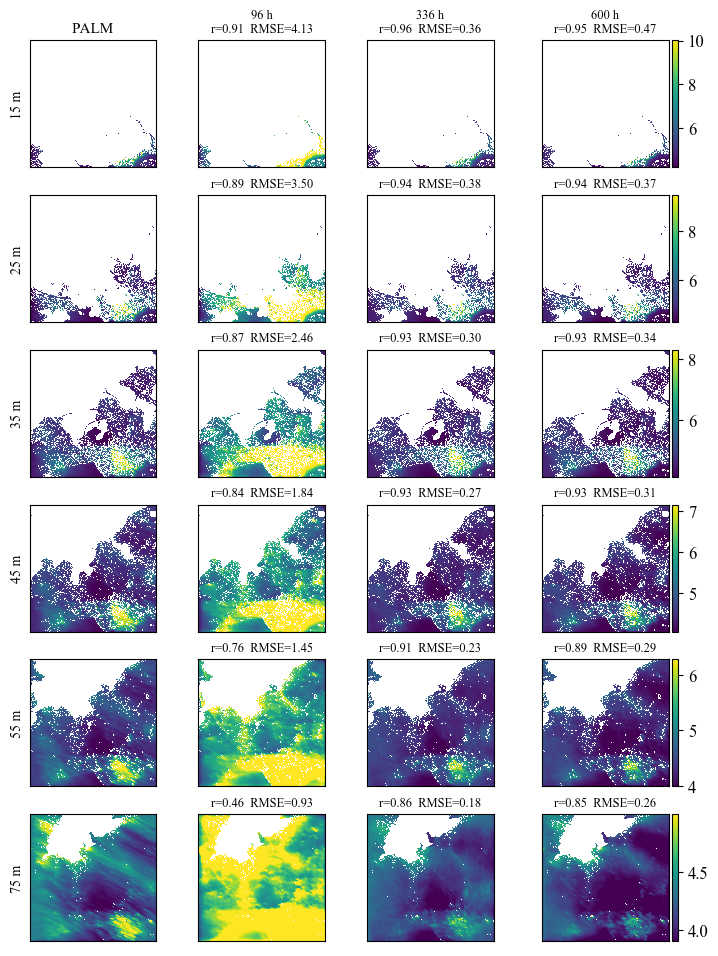

In [3]:
# 3-model comparison (96 / 336 / 600 h): PALM | predictions per level, per-level r & RMSE. lower levels (15-75 m)
SEL=[(0,'96 h'),(1,'336 h'),(2,'600 h')]       # indices into MODELS / preds
LVLS=[z for z in range(NZ) if ZH[z]<=75]
nrows=len(LVLS); ncol=1+len(SEL)
fig,axes=plt.subplots(nrows,ncol,figsize=(ncol*2.15,nrows*1.95))
for ri,z in enumerate(LVLS):
    sel=mask[z]
    if sel.sum()>=10:
        a=truth[z][sel].astype(np.float64)
        vmin=float(np.percentile(a,1)); vmax=float(np.percentile(a,99)); vmax=vmax if vmax>vmin else vmin+1e-6
    else: vmin,vmax=0.,1.
    cols=[('PALM',truth[z],None)]+[(lab,preds[i][z],i) for i,lab in SEL]
    for c,(lab,fld,mi) in enumerate(cols):
        ax=axes[ri,c]; ax.set_xticks([]); ax.set_yticks([])
        im=ax.imshow(np.where(sel,fld,np.nan),cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        if c==0:
            ax.set_ylabel(f'{ZH[z]} m',fontsize=10)
            if ri==0: ax.set_title('PALM',fontsize=11)
        else:
            if sel.sum()>=10:
                b=fld[sel].astype(np.float64); r=pc(a,b); rm=float(np.sqrt(np.mean((b-a)**2)))
            else: r,rm=np.nan,np.nan
            ax.set_title((f'{lab}\n' if ri==0 else '')+f'r={r:.2f}  RMSE={rm:.2f}',fontsize=9)
    fig.colorbar(im,ax=axes[ri,ncol-1],fraction=0.046,pad=0.02)
fig.subplots_adjust(wspace=0.05,hspace=0.22)
os.makedirs('figs',exist_ok=True)
fig.savefig('figs/case_jan08_3models_perlevel.png',dpi=300,bbox_inches='tight',pad_inches=0.04)
print('saved figs/case_jan08_3models_perlevel.png'); plt.show()

## Case figure - upper levels (95-195 m)

saved figs/case_jan08_3models_perlevel_high.png


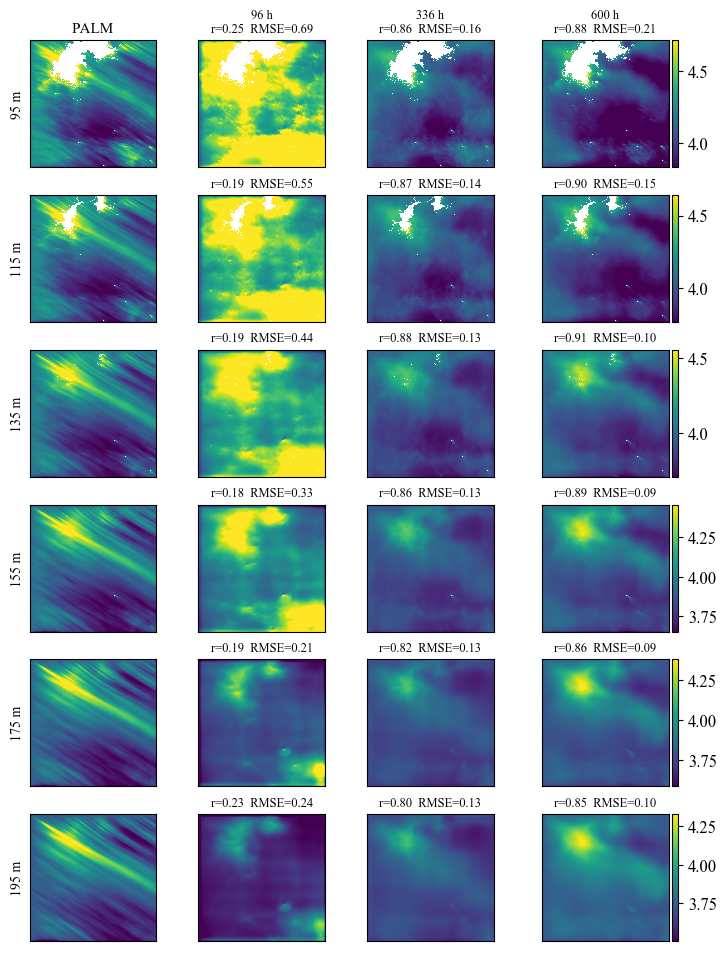

In [4]:
# 3-model comparison (96 / 336 / 600 h): PALM | predictions per level, per-level r & RMSE. upper levels (95-195 m)
SEL=[(0,'96 h'),(1,'336 h'),(2,'600 h')]       # indices into MODELS / preds
LVLS=[z for z in range(NZ) if ZH[z]>75]
nrows=len(LVLS); ncol=1+len(SEL)
fig,axes=plt.subplots(nrows,ncol,figsize=(ncol*2.15,nrows*1.95))
for ri,z in enumerate(LVLS):
    sel=mask[z]
    if sel.sum()>=10:
        a=truth[z][sel].astype(np.float64)
        vmin=float(np.percentile(a,1)); vmax=float(np.percentile(a,99)); vmax=vmax if vmax>vmin else vmin+1e-6
    else: vmin,vmax=0.,1.
    cols=[('PALM',truth[z],None)]+[(lab,preds[i][z],i) for i,lab in SEL]
    for c,(lab,fld,mi) in enumerate(cols):
        ax=axes[ri,c]; ax.set_xticks([]); ax.set_yticks([])
        im=ax.imshow(np.where(sel,fld,np.nan),cmap='viridis',vmin=vmin,vmax=vmax,origin='lower')
        if c==0:
            ax.set_ylabel(f'{ZH[z]} m',fontsize=10)
            if ri==0: ax.set_title('PALM',fontsize=11)
        else:
            if sel.sum()>=10:
                b=fld[sel].astype(np.float64); r=pc(a,b); rm=float(np.sqrt(np.mean((b-a)**2)))
            else: r,rm=np.nan,np.nan
            ax.set_title((f'{lab}\n' if ri==0 else '')+f'r={r:.2f}  RMSE={rm:.2f}',fontsize=9)
    fig.colorbar(im,ax=axes[ri,ncol-1],fraction=0.046,pad=0.02)
fig.subplots_adjust(wspace=0.05,hspace=0.22)
os.makedirs('figs',exist_ok=True)
fig.savefig('figs/case_jan08_3models_perlevel_high.png',dpi=300,bbox_inches='tight',pad_inches=0.04)
print('saved figs/case_jan08_3models_perlevel_high.png'); plt.show()